# Measuring importance among correlated predictors

Two identical predictors can each appear unimportant under one-at-a-time permutation because the untouched copy preserves the information:

$$
X_2=X_1
\quad\Longrightarrow\quad
\operatorname{MDA}_1\approx0,
\quad
\operatorname{MDA}_2\approx0
\quad\text{when either copy can replace the other.}
$$

Here, $X_1,X_2$ are identical predictors; $\Longrightarrow$ indicates the resulting substitution effect. $\operatorname{MDA}_1,\operatorname{MDA}_2$ are their separate permutation score decreases; $\approx0$ means close to zero in a fitted finite sample.

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"1.1.0"
configure_plots!()
paths = output_paths("14_feature_importance");
using CSV, TOML, Printf
include(joinpath("..","support","BookForest.jl"))
using RiskLabAI.Features: feature_importance_mdi,feature_importance_mda,feature_importance_sfi,clustered_feature_importance_mdi,clustered_feature_importance_mda,orthogonal_features,calculate_weighted_tau,mdi_plus_importance,conditional_predictive_impact
data_path = dataset_path("french_49_industries")
@assert isfile(data_path)
public_lines = readlines(data_path)
header_row = findfirst(startswith(",Agric"),public_lines)
end_row = findnext(line->isempty(strip(line)),public_lines,header_row+1)
raw = CSV.read(IOBuffer(join(public_lines[header_row:end_row-1],"\n")),DataFrame)
rename!(raw,names(raw)[1]=>"Date")
all_dates = Date.(string.(raw.Date),dateformat"yyyymmdd")
all_returns = Matrix{Float64}(raw[:,2:end])
valid = (Date(2019,1,1).<=all_dates).&(all_dates.<=Date(2025,12,31)).&vec(all((all_returns.!=-99.99).&(all_returns.!=-999.0);dims=2))
industry_dates = all_dates[valid]
industry_names = names(raw)[2:end]
industry_returns = all_returns[valid,:]./100
violet = "#C084FC"


selected_features = ["Food","Beer","Hshld","Oil","Coal","Mines","Hardw","Softw","Chips","Banks","Insur","Fin"]
cluster_names = ["Consumer","Resources","Technology","Finance"]
clusters = [name=>collect(3index-2:3index) for (index,name) in enumerate(cluster_names)]
columns = [findfirst(==(name),industry_names) for name in selected_features]

"""Match the public rolling sum's separate add/remove Kahan compensations."""
function rolling_sum(values,window)
    all(isfinite,values) || throw(ArgumentError("complete finite observations are required"))
    result = fill(NaN,length(values))
    total,add_compensation,remove_compensation = 0.,0.,0.
    previous,consecutive = first(values),0
    for index in eachindex(values)
        if index>window
            correction = -values[index-window]-remove_compensation
            updated = total+correction
            remove_compensation = (updated-total)-correction
            total = updated
        end
        value = values[index]
        correction = value-add_compensation
        updated = total+correction
        add_compensation = (updated-total)-correction
        total = updated
        consecutive = value==previous ? consecutive+1 : 1
        previous = value
        if index>=window
            result[index] = consecutive>=window ? previous*window : total
        end
    end
    return result
end

public_x = hcat([rolling_sum(industry_returns[:,column],5)[5:end-1] for column in columns]...)
public_y = Int.(vec(mean(industry_returns[6:end,:];dims=2)).>0)
public_dates = industry_dates[6:end]
input_root = joinpath("..","data","chapter14_random_inputs")
manifest_path = joinpath(input_root,"inputs.toml")
input_manifest = TOML.parsefile(manifest_path)["files"]
input_cache = Dict{String,DataFrame}()
audit_context = Ref("")
audit_fits,audit_nodes,audit_importances,audit_predictions = NamedTuple[],NamedTuple[],NamedTuple[],NamedTuple[]
audit_models = IdDict{Any,Int}()
audit_calls = Dict{Int,Int}()

function primitive(name)
    filename = name*".csv"
    return get!(input_cache,filename) do
        path = joinpath(input_root,filename)
        CSV.read(path,DataFrame)
    end
end

forest(seed;trees=120,depth=5,leaf=10,features=1) = (;seed,trees,depth=depth===nothing ? typemax(Int32) : depth,leaf,features=features===nothing ? 0 : features)

function begin_audit(name)
    audit_context[] = name
    foreach(empty!,(audit_fits,audit_nodes,audit_importances,audit_predictions,audit_models,audit_calls))
    return nothing
end

function fit_native(estimator,x,y,weights)
    specification = estimator isa BookForest.ClassificationForest ? estimator.specification : estimator
    @assert weights===nothing || all(==(1),weights)
    plan = Matrix{Int}(primitive("forest_$(specification.seed)_$(length(y))_$(Int(weights!==nothing))"))
    fitted = BookForest.fit_forest(specification,x,y,plan[3:end,:],vec(plan[2,:]))
    fit = length(audit_fits)+1
    audit_models[fitted] = fit
    audit_calls[fit] = 0
    push!(audit_fits,(fit=fit,seed=specification.seed,observations=length(y),features=size(x,2),trees=specification.trees,depth=specification.depth,leaf=specification.leaf,max_features=specification.features,weighted=weights!==nothing))
    for (tree_index,tree) in enumerate(fitted.trees)
        for (index,node) in enumerate(tree.nodes)
            push!(audit_nodes,(fit=fit,tree=tree_index,node=index,feature=node.feature,threshold=node.threshold,left=node.left,right=node.right,count=node.count,mass=node.mass,positive=node.positive_mass,impurity=node.impurity))
        end
        for (feature,value) in enumerate(tree.importance)
            push!(audit_importances,(fit=fit,tree=tree_index,feature=feature,importance=value))
        end
    end
    return fitted
end

function predict_native(model,x)
    probabilities = BookForest.predict_proba(model,x)
    fit = audit_models[model]
    audit_calls[fit] += 1
    append!(audit_predictions,[(fit=fit,call=audit_calls[fit],row=index,p0=probabilities[index,1],p1=probabilities[index,2]) for index in axes(x,1)])
    return probabilities
end

function finish_audit()
    prefix = audit_context[]
    for (suffix,records) in [("fits",audit_fits),("nodes",audit_nodes),("tree_importance",audit_importances),("predictions",audit_predictions)]
        isempty(records) || save_data(DataFrame(records),paths,prefix*"_"*suffix)
    end
    return nothing
end

function saved_importance(name,result,labels)
    save_data(DataFrame(Feature=labels,Mean=result.mean,StandardDeviation=result.std),paths,name*"_importance")
    finish_audit()
    return result
end

function fixed_folds(seed)
    membership = primitive("folds_$(seed)").fold
    return [(findall(!=(fold),membership),findall(==(fold),membership)) for fold in 1:maximum(membership)]
end

function mdi(name,x,y,estimator;groups=nothing,labels=string.(axes(x,2)))
    begin_audit(name)
    options = (;fit_estimator=fit_native,tree_importances=BookForest.tree_importances)
    result = groups===nothing ? feature_importance_mdi(estimator,x,y;options...) : clustered_feature_importance_mdi(estimator,x,y,groups;options...)
    return saved_importance(name,result,labels)
end

function mda(name,x,y,estimator,seed;groups=nothing,labels=string.(axes(x,2)))
    begin_audit(name)
    folds = fixed_folds(seed)
    values = Matrix{Int}(primitive("permutations_$(seed)"))
    permutations = [[values[values[:,1].==fold,column] for column in 2:size(values,2)] for fold in eachindex(folds)]
    options = (;fit_estimator=fit_native,predict_proba=predict_native,estimator_classes=_->[0,1],folds,permutations,n_splits=length(folds),random_state=seed)
    result = groups===nothing ? feature_importance_mda(estimator,x,y;options...) : clustered_feature_importance_mda(estimator,x,y,groups;options...)
    return saved_importance(name,result,labels)
end

function sfi(name,x,y,estimator;labels=string.(axes(x,2)))
    begin_audit(name)
    result = feature_importance_sfi(estimator,x,y;fit_estimator=fit_native,predict=(model,values)->Int.(predict_native(model,values)[:,2].>.5),scoring=:accuracy,n_splits=5)
    return saved_importance(name,result,labels)
end

function table(frame,name,caption)
    save_table(frame,paths,name;caption,label="tab:chapter12-"*replace(name,"_"=>"-"))
    return nothing
end

function standard_panels(frame,label,title,name)
    order = sortperm(frame.MDI)
    panels = []
    for (column,color) in zip(["MDI","MDA log-loss decrease","SFI accuracy"],[palette.cyan,palette.amber,palette.green])
        lower,upper = min(0,minimum(frame[!,column])),max(0,maximum(frame[!,column]))
        span = max(upper-lower,eps(Float64))
        panel = bar(1:nrow(frame),frame[order,column];orientation=:h,yticks=(1:nrow(frame),frame[order,label]),color,linealpha=0,alpha=.85,legend=false,title=column,xlabel="Score",ylims=(.4,nrow(frame)+.6),xlims=(lower-.04span,upper+.12span),left_margin=5Plots.mm)
        vline!(panel,[0.];color=palette.text,linewidth=.8,label=false)
        push!(panels,panel)
    end
    save_figure(plot(panels...;layout=(1,3),size=(1500,650),plot_title=title,plot_titlefontsize=13),paths,name)
    return nothing
end

public_frame = hcat(DataFrame(Date=public_dates,Target=public_y),DataFrame(public_x,selected_features))
save_data(public_frame,paths,"public_predictors");


## Public Dependence Groups

Row,Cluster,Features,Mean within-cluster correlation
,String,String,Float64
1,Consumer,"Food, Beer, Hshld",0.742331
2,Resources,"Oil, Coal, Mines",0.527364
3,Technology,"Hardw, Softw, Chips",0.760295
4,Finance,"Banks, Insur, Fin",0.756251


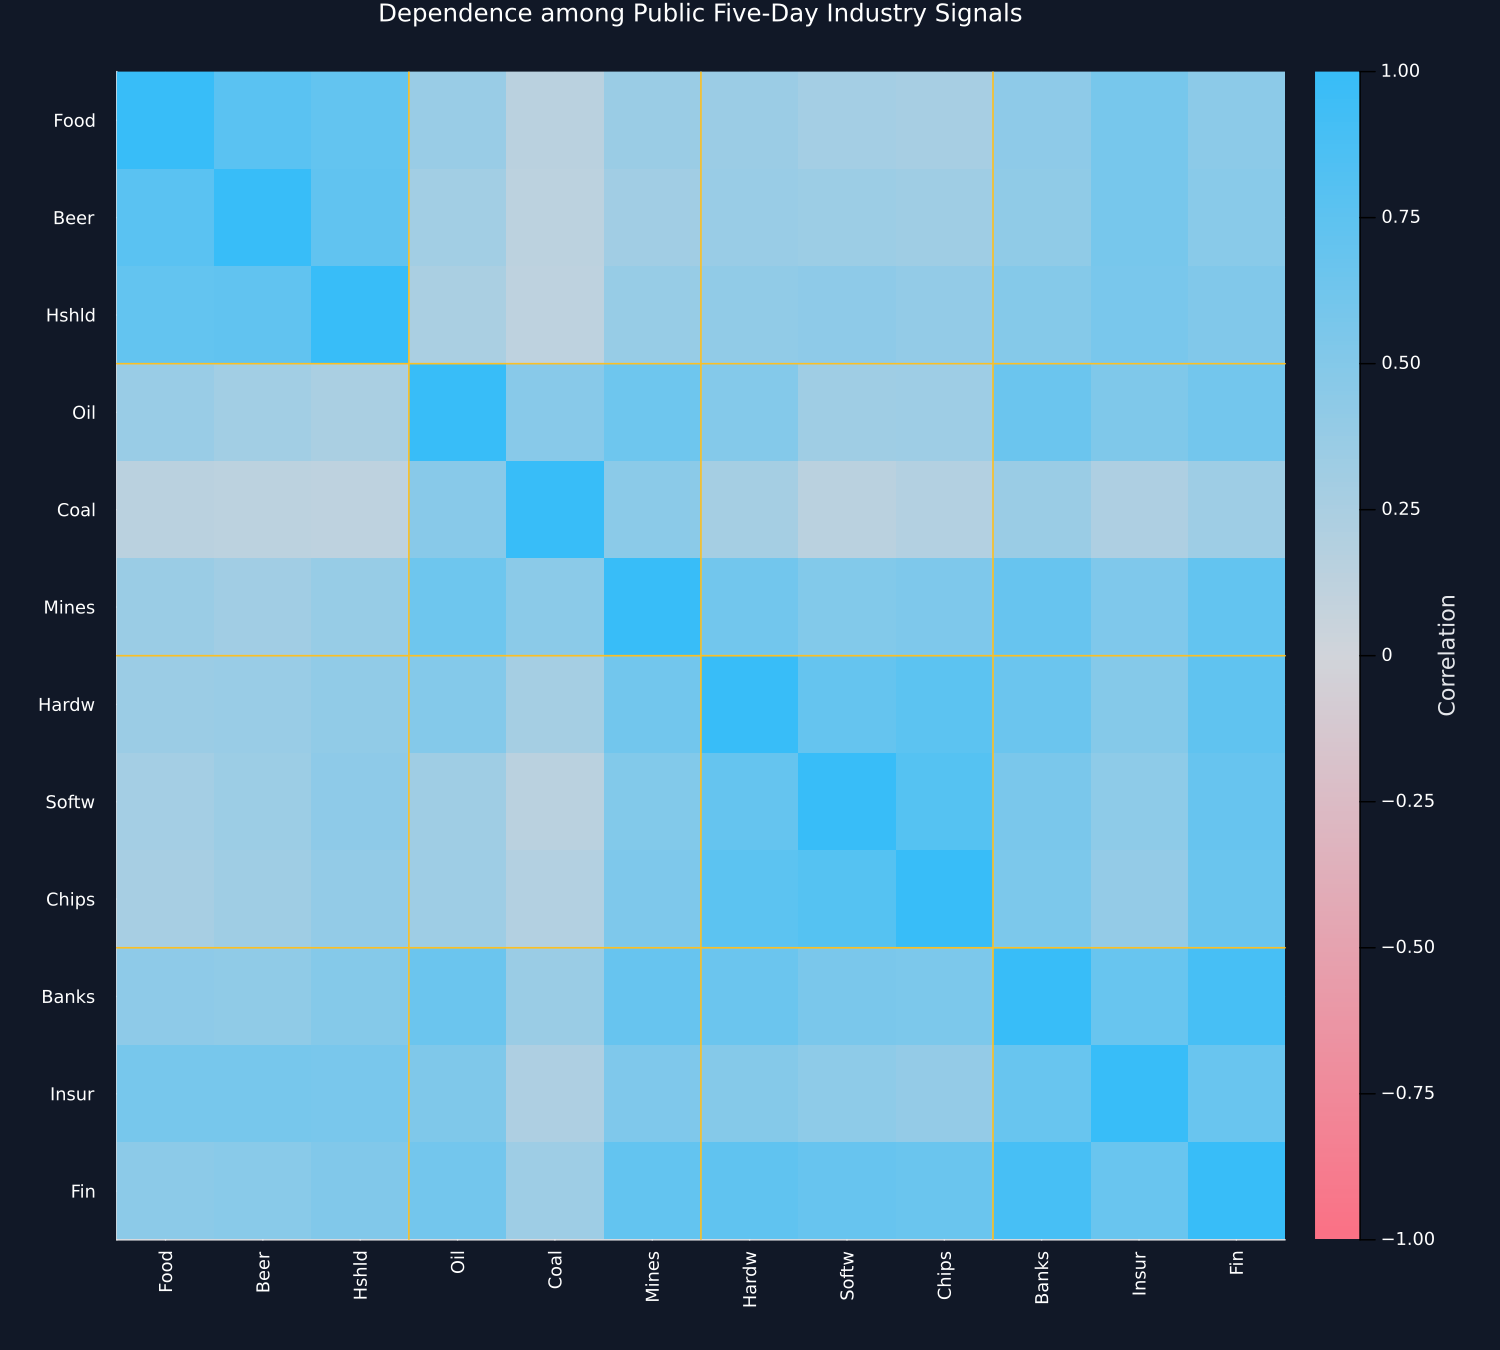

In [2]:
public_correlation = cor(public_x)
within_correlations = [mean([public_correlation[left,right] for left in last(group),right in last(group) if left<right]) for group in clusters]
public_cluster_map = DataFrame("Cluster"=>cluster_names,"Features"=>[join(selected_features[last(group)],", ") for group in clusters],"Mean within-cluster correlation"=>within_correlations)
table(public_cluster_map,"public_cluster_map","Public industry groups and their within-group dependence.")
save_data(DataFrame(public_correlation,selected_features),paths,"public_cluster_correlation")
figure = heatmap(1:12,1:12,public_correlation;color=cgrad([palette.rose,"#D1D5DB",palette.cyan]),clims=(-1,1),xticks=(1:12,selected_features),yticks=(1:12,selected_features),xrotation=90,yflip=true,aspect_ratio=:equal,xlims=(.5,12.5),ylims=(.5,12.5),widen=false,title="Dependence among Public Five-Day Industry Signals",colorbar_title="Correlation",size=(1000,900))
for boundary in [3.5,6.5,9.5]
    hline!(figure,[boundary];color=palette.amber,linewidth=1.1,label=false)
    vline!(figure,[boundary];color=palette.amber,linewidth=1.1,label=false)
end
save_figure(figure,paths,"public_cluster_correlation")


## Comparing grouped importance estimates

Grouped MDI adds the split credit inside a group, while grouped MDA jointly reorders all features in that group:

$$
\operatorname{MDI}_{G}=\sum_{j\in G}\operatorname{MDI}_j,
\qquad
\operatorname{MDA}_{G}
=\frac{1}{K}\sum_{k=1}^{K}\left(S_k-S_{k,G}^{\pi}\right).
$$

Here, $G$ is a chosen feature group; $j\in G$ means feature $j$ belongs to it; $K$ is the number of folds. $S_k$ is the original held-out score; $S_{k,G}^{\pi}$ is the score after one common row permutation is applied to the columns in $G.$ $\operatorname{MDI}_{G}$ and $\operatorname{MDA}_{G}$ are the group-level impurity and predictive-score summaries.

Row,Cluster,Clustered MDI,Clustered MDA log-loss decrease
,String,Float64,Float64
1,Consumer,0.270494,0.000125661
2,Resources,0.24726,0.00163618
3,Technology,0.227676,0.000282364
4,Finance,0.25457,0.000876152


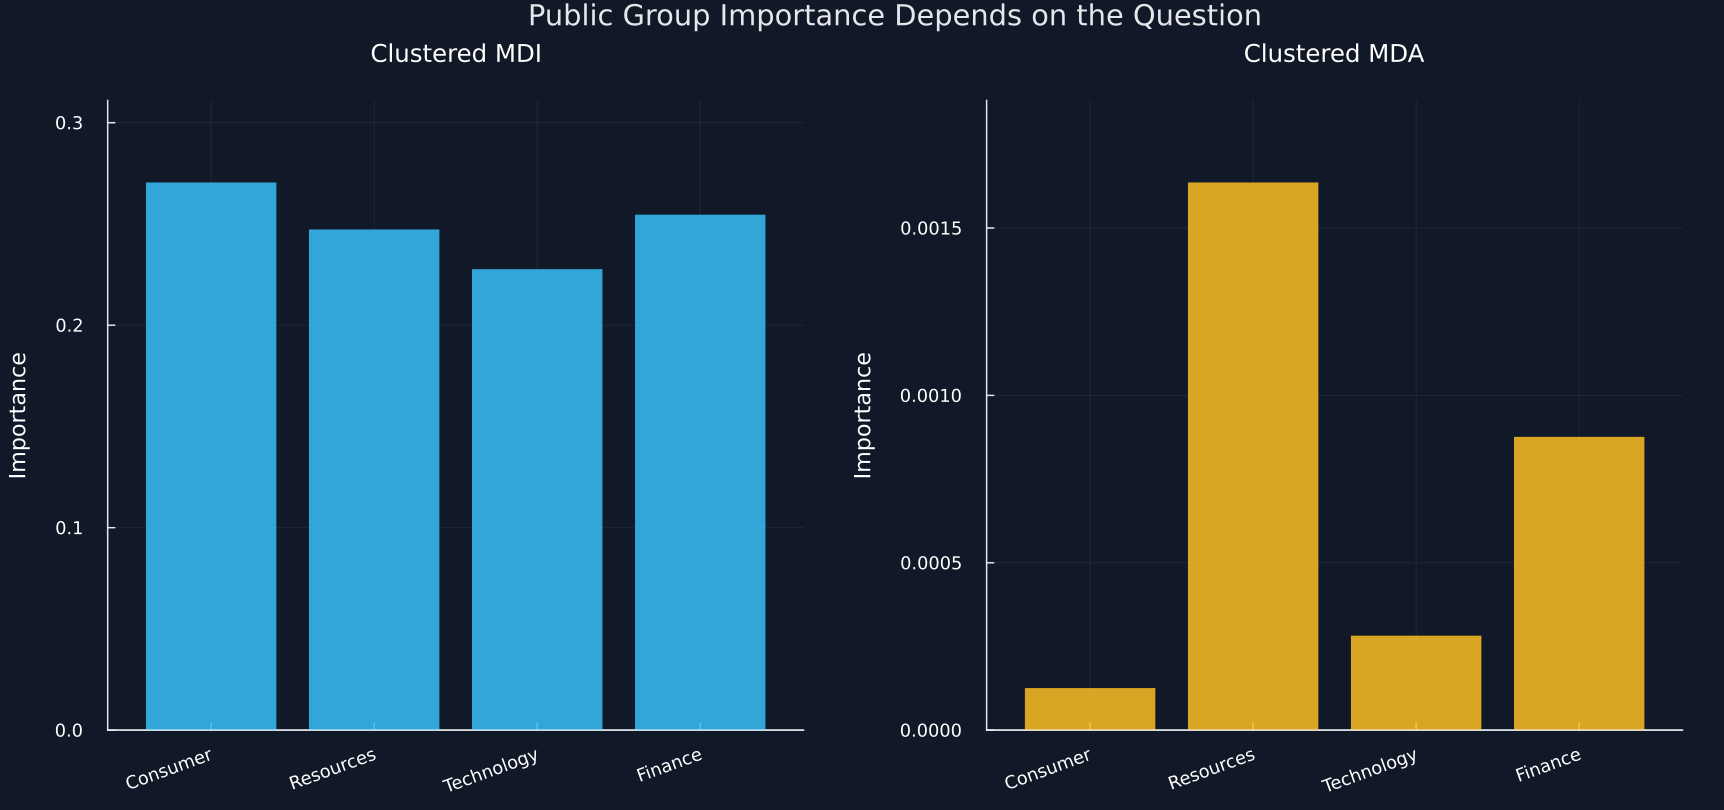

In [3]:
public_clustered_mdi = mdi("public_clustered_mdi",public_x,public_y,forest(1231);groups=clusters,labels=cluster_names)
public_clustered_mda = mda("public_clustered_mda",public_x,public_y,forest(1232),1233;groups=clusters,labels=cluster_names)
public_cluster_importance = DataFrame("Cluster"=>cluster_names,"Clustered MDI"=>public_clustered_mdi.mean,"Clustered MDA log-loss decrease"=>public_clustered_mda.mean)
table(public_cluster_importance,"public_cluster_importance","Clustered importance on public industry signals.")
panels = [bar(1:4,values;xticks=(1:4,cluster_names),xrotation=20,color,linealpha=0,alpha=.85,legend=false,title,ylabel="Importance",ylims=(min(0,minimum(values))*1.15,maximum(values)*1.15)) for (values,color,title) in [(public_clustered_mdi.mean,palette.cyan,"Clustered MDI"),(public_clustered_mda.mean,palette.amber,"Clustered MDA")]]
for panel in panels
    hline!(panel,[0.];color=palette.text,linewidth=.8,label=false)
end
save_figure(plot(panels...;layout=(1,2),size=(1150,540),plot_title="Public Group Importance Depends on the Question",plot_titlefontsize=13),paths,"public_cluster_importance")


## A Fixed Information Set with More Copies

The experiment repeats exactly the same signal several times without adding any new information about the label:

$$
X_1=\cdots=X_q=Z,
\qquad
Y=\mathbf 1\!\left\{1.5Z+0.9\varepsilon>0\right\},
\qquad
q\in\{1,2,4,8\}.
$$

Here, $q$ is the number of identical signal columns; $X_1,\ldots,X_q$ are those columns; $Z$ is their shared standard-normal value. $Y$ is the binary label; $\varepsilon$ is an independent standard-normal shock; $1.5$ is signal strength; $0.9$ is label-noise scale.

Row,Signal copies,Largest individual MDI,Summed individual MDI,Clustered MDI,Largest individual MDA,Summed individual MDA,Clustered MDA
,Int64,Float64,Float64,Float64,Float64,Float64,Float64
1,1,0.868704,0.868704,0.868293,1.87223,1.87223,1.77203
2,2,0.441545,0.869574,0.864623,0.174652,0.316566,1.65657
3,4,0.259171,0.875362,0.866288,0.0417019,0.115611,1.40478
4,8,0.150124,0.902274,0.86653,0.0358859,0.184669,1.52045


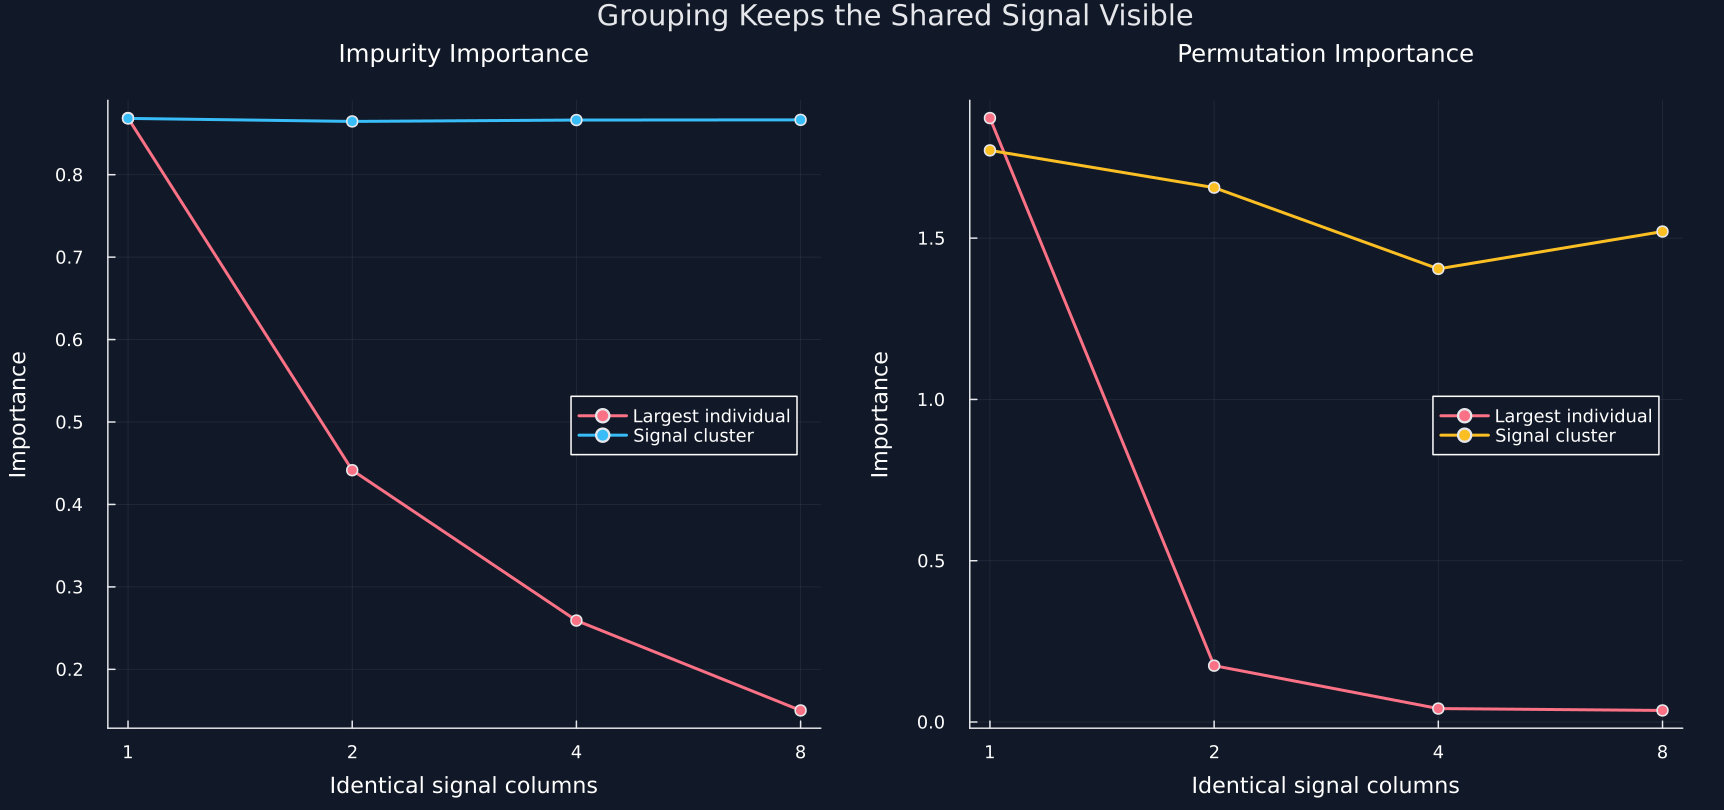

In [4]:
duplicate_rows = NamedTuple[]
draws = primitive("duplicate_draws")
duplicate_y = Int.((1.5draws.latent_signal.+.9draws.target_noise).>0)
for count in [1,2,4,8]
    duplicate_x = hcat(repeat(draws.latent_signal,1,count),Matrix(draws[:,3:6]))
    duplicate_names = vcat(["Signal $index" for index in 1:count],["Noise $index" for index in 1:4])
    duplicate_groups = ["Signal"=>collect(1:count),"Noise"=>collect(count+1:count+4)]
    full_forest(seed) = forest(seed;depth=6,leaf=8,features=nothing)
    ordinary_mdi = mdi("duplicate_$(count)_mdi",duplicate_x,duplicate_y,full_forest(13010+count);labels=duplicate_names)
    ordinary_mda = mda("duplicate_$(count)_mda",duplicate_x,duplicate_y,full_forest(13020+count),13030+count;labels=duplicate_names)
    grouped_mdi = mdi("duplicate_$(count)_clustered_mdi",duplicate_x,duplicate_y,full_forest(13040+count);groups=duplicate_groups,labels=["Signal","Noise"])
    grouped_mda = mda("duplicate_$(count)_clustered_mda",duplicate_x,duplicate_y,full_forest(13050+count),13060+count;groups=duplicate_groups,labels=["Signal","Noise"])
    push!(duplicate_rows,(copies=count,largest_mdi=maximum(ordinary_mdi.mean[1:count]),summed_mdi=sum(ordinary_mdi.mean[1:count]),clustered_mdi=grouped_mdi.mean[1],largest_mda=maximum(ordinary_mda.mean[1:count]),summed_mda=sum(ordinary_mda.mean[1:count]),clustered_mda=grouped_mda.mean[1]))
    save_data(hcat(DataFrame(Target=duplicate_y),DataFrame(duplicate_x,duplicate_names)),paths,"duplicate_$(count)_predictors")
end
controlled_substitution = DataFrame(duplicate_rows)
rename!(controlled_substitution,["Signal copies","Largest individual MDI","Summed individual MDI","Clustered MDI","Largest individual MDA","Summed individual MDA","Clustered MDA"])
table(controlled_substitution,"controlled_substitution","Identical-signal substitution as the number of copies grows.")
panels = []
for (title,individual,clustered,color) in [("Impurity Importance","Largest individual MDI","Clustered MDI",palette.cyan),("Permutation Importance","Largest individual MDA","Clustered MDA",palette.amber)]
    panel = plot([1,2,4,8],controlled_substitution[!,individual];marker=:circle,color=palette.rose,label="Largest individual",xscale=:log2,xticks=([1,2,4,8],["1","2","4","8"]),xlabel="Identical signal columns",ylabel="Importance",title,legend=:right)
    plot!(panel,[1,2,4,8],controlled_substitution[!,clustered];marker=:circle,color,label="Signal cluster")
    push!(panels,panel)
end
save_figure(plot(panels...;layout=(1,2),size=(1150,540),plot_title="Grouping Keeps the Shared Signal Visible",plot_titlefontsize=13),paths,"controlled_substitution")


## Tests

In [5]:
@assert size(public_correlation)==(12,12)
@assert diag(public_correlation)≈ones(12)
@assert public_correlation≈transpose(public_correlation)
@assert size(public_cluster_map)==(4,3)
@assert minimum(within_correlations)>.45
@assert sort(reduce(vcat,last.(clusters)))==collect(1:12)
@assert length(public_clustered_mdi.mean)==length(public_clustered_mdi.std)==4
@assert sum(public_clustered_mdi.mean)≈1
@assert length(public_clustered_mda.mean)==length(public_clustered_mda.std)==4
@assert size(public_cluster_importance)==(4,3)
@assert size(controlled_substitution)==(4,7)
@assert controlled_substitution[!,"Signal copies"]==[1,2,4,8]
@assert controlled_substitution[end,"Largest individual MDI"]<controlled_substitution[1,"Largest individual MDI"]/4
@assert controlled_substitution[end,"Largest individual MDA"]<controlled_substitution[1,"Largest individual MDA"]/10
@assert minimum(controlled_substitution[!,"Clustered MDI"])>.8
@assert minimum(controlled_substitution[2:end,"Clustered MDA"])>1
@assert controlled_substitution[end,"Summed individual MDA"]<controlled_substitution[end,"Clustered MDA"]/5
@assert isfile(joinpath(paths.figures,"public_cluster_correlation.pdf"))
@assert isfile(joinpath(paths.figures,"public_cluster_importance.pdf"))
@assert isfile(joinpath(paths.figures,"controlled_substitution.pdf"))
@assert isfile(joinpath(paths.tables,"public_cluster_map.tex"))
@assert isfile(joinpath(paths.tables,"public_cluster_importance.tex"))
@assert isfile(joinpath(paths.tables,"controlled_substitution.tex"))
